In [23]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
df = pd.read_csv('../data/processed/final_data.csv')

In [17]:
display(df.info(memory_usage='deep'))
display(df.head(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   order_id            99441 non-null  object 
 1   customer_unique_id  99441 non-null  object 
 2   customer_state      99441 non-null  object 
 3   order_status        99441 non-null  object 
 4   purchased_at        99441 non-null  object 
 5   delivered_at        96476 non-null  object 
 6   estimated_at        99441 non-null  object 
 7   items_count         98666 non-null  float64
 8   items_value         98666 non-null  float64
 9   freight_value       98666 non-null  float64
 10  payment_value       99440 non-null  float64
 11  review_score        98673 non-null  float64
dtypes: float64(5), object(7)
memory usage: 48.7 MB


None

,order_id,customer_unique_id,customer_state,order_status,purchased_at,delivered_at,estimated_at,items_count,items_value,freight_value,payment_value,review_score
0,00018f77f2f0320c557190d7a144bdd3,eb28e67c4c0b83846050ddfb8a35d051,SP,delivered,2017-04-26 10:53:06,2017-05-12 16:04:24,2017-05-15 00:00:00,1.0,239.90,19.93,259.83,4.0
1,000229ec398224ef6ca0657da4fc703e,3818d81c6709e39d06b2738a8d3a2474,MG,delivered,2018-01-14 14:33:31,2018-01-22 13:19:16,2018-02-05 00:00:00,1.0,199.00,17.87,216.87,5.0
2,00024acbcdf0a6daa1e931b038114c75,af861d436cfc08b2c2ddefd0ba074622,SP,delivered,2018-08-08 10:00:35,2018-08-14 13:32:39,2018-08-20 00:00:00,1.0,12.99,12.79,25.78,4.0


In [18]:
# Перетворюємо текст на дати
for col in ['purchased_at', 'delivered_at', 'estimated_at']:
    df[col] = pd.to_datetime(df[col])

In [20]:
print('Дублікати order_id:', df['order_id'].duplicated().sum())   # має бути 0
print("\n")
print(df.isna().sum())
print("\n")# пропуски по колонках
print(df['order_status'].value_counts())                          # статуси
df.describe()                                                     # мін, макс, середнє

Дублікати order_id: 0


order_id                 0
customer_unique_id       0
customer_state           0
order_status             0
purchased_at             0
delivered_at          2965
estimated_at             0
items_count            775
items_value            775
freight_value          775
payment_value            1
review_score           768
dtype: int64


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


,purchased_at,delivered_at,estimated_at,items_count,items_value,freight_value,payment_value,review_score
count,99441,96476,99441,98666.000000,98666.000000,98666.000000,99440.000000,98673.000000
mean,2017-12-31 08:43:12.776581120,2018-01-14 12:09:19.035542528,2018-01-24 03:08:37.730111232,1.141731,137.754076,22.823562,160.990267,4.086793
min,2016-09-04 21:15:19,2016-10-11 13:46:32,2016-09-30 00:00:00,1.000000,0.850000,0.000000,0.000000,1.000000
25%,2017-09-12 14:46:19,2017-09-25 22:07:22.249999872,2017-10-03 00:00:00,1.000000,45.900000,13.850000,62.010000,4.000000
50%,2018-01-18 23:04:36,2018-02-02 19:28:10.500000,2018-02-15 00:00:00,1.000000,86.900000,17.170000,105.290000,5.000000
75%,2018-05-04 15:42:16,2018-05-15 22:48:52.249999872,2018-05-25 00:00:00,1.000000,149.900000,24.040000,176.970000,5.000000
max,2018-10-17 17:30:18,2018-10-17 13:22:46,2018-11-12 00:00:00,21.000000,13440.000000,1794.960000,13664.080000,5.000000
std,NaN,NaN,NaN,0.538452,210.645145,21.650909,221.951257,1.346274


In [21]:
df[df['delivered_at'].isna()]['order_status'].value_counts()

order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

In [22]:
# Беремо лише доставлені замовлення з відомою датою доставки
delivered = df[(df['order_status'] == 'delivered') & df['delivered_at'].notna()].copy()

# Скільки днів доставляли
delivered['delivery_days'] = (delivered['delivered_at'] - delivered['purchased_at']).dt.days

# Затримка відносно обіцяної дати
delivered['delay_days'] = (delivered['delivered_at'].dt.normalize()
                           - delivered['estimated_at'].dt.normalize()).dt.days

delivered['is_late'] = delivered['delay_days'] > 0

delivered[['delivery_days', 'delay_days', 'is_late']].describe()

,delivery_days,delay_days
count,96470.000000,96470.000000
mean,12.093604,-11.875889
std,9.551380,10.182105
min,0.000000,-147.000000
25%,6.000000,-17.000000
50%,10.000000,-12.000000
75%,15.000000,-7.000000
max,209.000000,188.000000


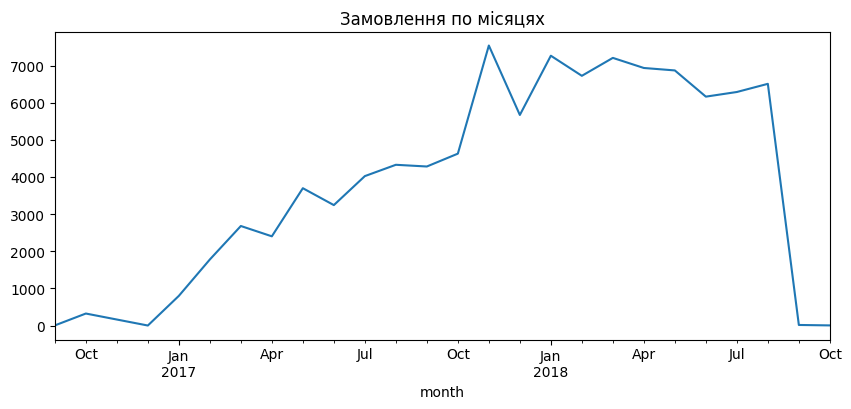

In [24]:
df['month'] = df['purchased_at'].dt.to_period('M')
monthly = df.groupby('month').size()

monthly.plot(kind='line', figsize=(10, 4), title='Замовлення по місяцях')
plt.show()

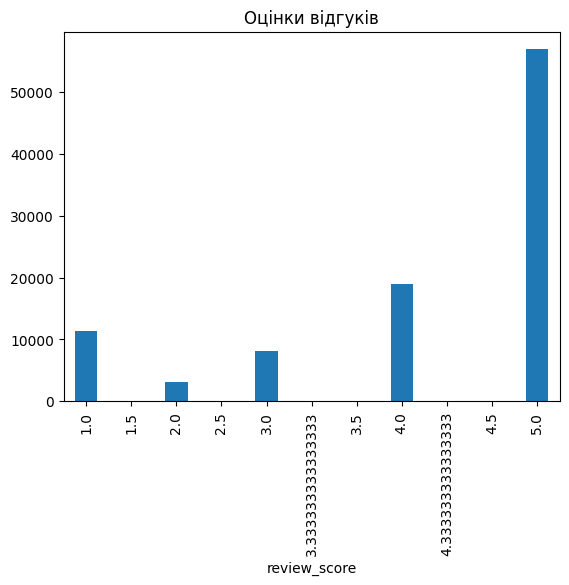

review_score
1.000000    11.5
1.500000     0.0
2.000000     3.2
2.500000     0.0
3.000000     8.2
3.333333     0.0
3.500000     0.0
4.000000    19.3
4.333333     0.0
4.500000     0.1
5.000000    57.7
Name: proportion, dtype: float64

In [25]:
reviewed = df.dropna(subset=['review_score'])

reviewed['review_score'].value_counts().sort_index().plot(kind='bar', title='Оцінки відгуків')
plt.show()

(reviewed['review_score'].value_counts(normalize=True).sort_index() * 100).round(1)

               count  mean
delay_group               
On time        89443  4.29
1-3 days late   1852  3.29
4-7 days late   1748  2.11
7+ days late    2781  1.70


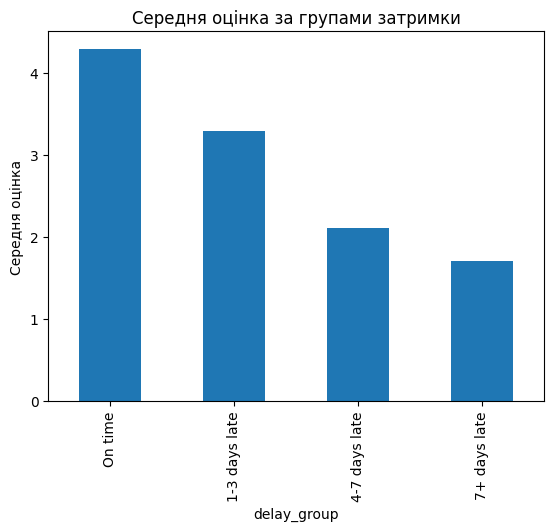

In [27]:
delivered_rev = delivered.dropna(subset=['review_score']).copy()

delivered_rev['delay_group'] = pd.cut(
    delivered_rev['delay_days'],
    bins=[-1000, 0, 3, 7, 1000],
    labels=['On time', '1-3 days late', '4-7 days late', '7+ days late']
)

result = delivered_rev.groupby('delay_group', observed=True)['review_score'].agg(['count', 'mean']).round(2)
print(result)

result['mean'].plot(kind='bar', title='Середня оцінка за групами затримки')
plt.ylabel('Середня оцінка')
plt.show()

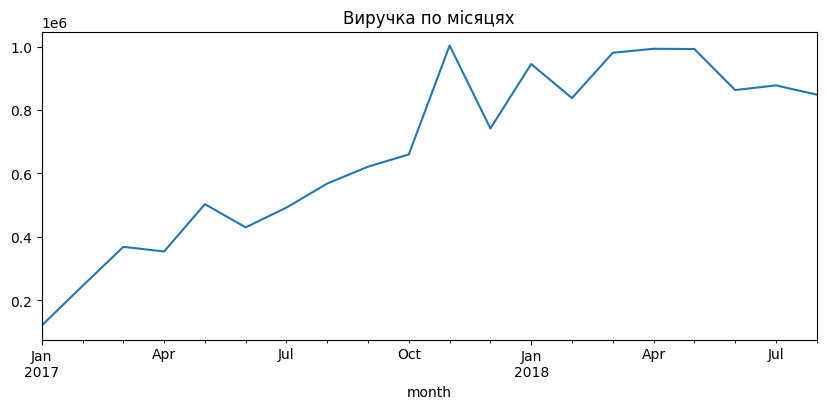

In [28]:
full = df[(df['purchased_at'] >= '2017-01-01') & (df['purchased_at'] < '2018-09-01')].copy()
full = full[~full['order_status'].isin(['canceled', 'unavailable'])]
full['month'] = full['purchased_at'].dt.to_period('M')

monthly_revenue = full.groupby('month')['items_value'].sum()
monthly_revenue.plot(figsize=(10, 4), title='Виручка по місяцях')
plt.show()

In [29]:
states = delivered.groupby('customer_state').agg(
    orders=('order_id', 'count'),
    late_rate=('is_late', 'mean')
)
states['late_rate'] = (states['late_rate'] * 100).round(1)
states[states['orders'] >= 500].sort_values('late_rate', ascending=False).head(10)

,orders,late_rate
customer_state,,
MA,717,17.4
CE,1279,13.8
BA,3256,12.2
RJ,12350,12.1
PA,946,11.2
ES,1995,10.7
PB,517,10.4
MS,701,9.7
PE,1593,9.6


In [30]:
orders_per_customer = df.groupby('customer_unique_id')['order_id'].count()
print(orders_per_customer.value_counts().sort_index())
print('Частка повторних клієнтів, %:', round((orders_per_customer > 1).mean() * 100, 2))

order_id
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64
Частка повторних клієнтів, %: 3.12
